# TP2 - Parte 1: dataset y preprocesamiento

Notebook de documentación y tratamiento del dataset **70 Dog Breeds Image Dataset**: análisis
exploratorio, control de calidad, conjunto independiente de evaluación, preprocesamiento,
data augmentation y splits (ver `ENUNCIADO.md`, sección 3).

Tiene que poder leerse como un informe: celdas Markdown que explican qué se hace y por qué,
código y salidas (gráficos y tablas) **ejecutadas y guardadas**. Una notebook sin salidas
visibles se considera no entregada.

Lo que produce esta notebook lo reutilizan `2-train.ipynb` y `train_classifier`: los splits
finales (CSV/JSON con rutas y etiquetas), el conjunto independiente y el preprocesamiento
encapsulado en un módulo de `src/lib/`.

**Notebook en Google Colab (si corresponde):** <reemplazar por el link, con permiso de lectura para los docentes>

Si entregan la notebook en Colab, esta copia del repositorio funciona como notebook de referencia:
el link de arriba es obligatorio y la notebook de Colab debe estar ejecutada, con sus salidas
(ver `ENUNCIADO.md`, sección 8.2).

## Equipo
- Alumno 1 :
- Alumno 2 :

## 1. Entorno

La notebook se ejecuta localmente desde la raíz del repositorio (entorno `cv2-venv`, con GPU), donde ya
están el dataset y los resultados intermedios. Si se abre en Colab, la celda siguiente clona el repositorio
e instala lo que falta; localmente no hace nada.

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # Completar con la URL del fork si se ejecuta en Colab.
    REPO_URL = "https://github.com/<usuario>/tuia-dog-recognition-app.git"
    !git clone $REPO_URL proyecto
    %cd proyecto
    !pip install -q pydantic-settings python-dotenv kagglehub albumentations imagehash ultralytics
print("Colab:", IN_COLAB)

Colab: False


## 2. Configuración

Las rutas se fijan como variables de entorno **antes** de importar `lib`: `src/.env` usa rutas relativas a
`src/` (es la configuración del backend local) y la notebook corre desde la raíz. Sin pgvector: esta notebook
no usa la base vectorial.

In [2]:
import logging
import os
from pathlib import Path

ROOT = Path.cwd()
assert (ROOT / "src" / "lib").is_dir(), "Ejecutar la notebook desde la raiz del repositorio"
os.environ.update(
    {
        "USE_PGVECTOR": "false",
        "DATA_PATH": str(ROOT / "data"),
        "DATASET_PATH": str(ROOT / "data" / "dataset"),
        "OUTPUT_PATH": str(ROOT / "output"),
        "MODEL_PATH": str(ROOT / "models"),
        "TORCH_HOME": str(ROOT / "models" / "torch"),
        "YOLO_MODEL": str(ROOT / "models" / "yolov8n.pt"),
    }
)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from lib.config import settings

logging.getLogger().setLevel(logging.WARNING)  # config.py configura INFO; en la notebook solo avisos
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 140)

DATASET = settings.dataset_path
SPLITS_DIR = settings.data_path / "splits"
CACHE = settings.output_path / "p1"  # mediciones intermedias, fuera de git
SEED = 42

print("dataset:", DATASET)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no")

dataset: C:\Users\lucas\Documents\TUIA\IA 5.1 - Vision por Computadora\tuia-dog-recognition-app\data\dataset
GPU: NVIDIA GeForce GTX 1050


## 3. Dataset

Se descarga con `scripts/download_dataset.py` (requiere credenciales de Kaggle) solo si no está.

In [3]:
if not (DATASET / "dogs.csv").exists():
    !python scripts/download_dataset.py
print(sorted(p.name for p in DATASET.iterdir() if not p.name.startswith(".")))

['dogs.csv', 'test', 'train', 'valid']


## 4. Descripción del dataset

**70 Dog Breeds-Image Data Set** (Kaggle, `gpiosenka/70-dog-breedsimage-data-set`), publicado por Gerry
(versión 2, julio de 2021). Según su descripción, las imágenes se obtuvieron con búsquedas por raza en
internet, el autor las revisó a mano para quitar las incorrectas y duplicadas, y las redimensionó a
224 x 224 x 3 en JPG. Viene dividido en `train/`, `valid/` y `test/` con una carpeta por raza, más
`dogs.csv` con ruta, etiqueta y split de cada imagen.

**Licencia:** CC0 (dominio público), según los metadatos del dataset en Kaggle. Permite el uso académico que
le damos. Matiz: CC0 lo declara quien armó el dataset, pero las fotos salen de búsquedas web y no se
documenta la licencia de cada foto original (ver sección 12).

El manifiesto `data/splits/splits_v0.csv` es `dogs.csv` normalizado (ruta, raza, split); es el punto de
partida de todo el análisis. Las razas se normalizan quitando espacios repetidos en el nombre.

In [4]:
from lib.dataset.manifest import class_names, load_manifest

v0 = load_manifest(SPLITS_DIR / "splits_v0.csv", dataset_path=DATASET, check_files=True)
summary = v0.groupby("split").agg(imagenes=("path", "size"), razas=("breed", "nunique")).reindex(["train", "valid", "test"])
summary.loc["total"] = [len(v0), v0["breed"].nunique()]
display(summary)
print("Razas:", len(class_names(v0)))
print(", ".join(class_names(v0)))

,imagenes,razas
split,,
train,7946,70
valid,700,70
test,700,70
total,9346,70


Razas: 70
Afghan, African Wild Dog, Airedale, American Hairless, American Spaniel, Basenji, Basset, Beagle, Bearded Collie, Bermaise, Bichon Frise, Blenheim, Bloodhound, Bluetick, Border Collie, Borzoi, Boston Terrier, Boxer, Bull Mastiff, Bull Terrier, Bulldog, Cairn, Chihuahua, Chinese Crested, Chow, Clumber, Cockapoo, Cocker, Collie, Corgi, Coyote, Dalmation, Dhole, Dingo, Doberman, Elk Hound, French Bulldog, German Sheperd, Golden Retriever, Great Dane, Great Perenees, Greyhound, Groenendael, Irish Spaniel, Irish Wolfhound, Japanese Spaniel, Komondor, Labradoodle, Labrador, Lhasa, Malinois, Maltese, Mex Hairless, Newfoundland, Pekinese, Pit Bull, Pomeranian, Poodle, Pug, Rhodesian, Rottweiler, Saint Bernard, Schnauzer, Scotch Terrier, Shar_Pei, Shiba Inu, Shih-Tzu, Siberian Husky, Vizsla, Yorkie


### 4.1 Mediciones que usan las secciones siguientes

Se mide una vez cada imagen y se guarda en `output/p1/` (fuera de git):

- **Calidad**: resolución, canales, nitidez (varianza del Laplaciano), brillo, contraste y pHash.
- **Embeddings** del baseline de la Etapa 1 (ResNet50 ImageNet, el mismo `BaselineEmbedder` de la app):
  sirven para encontrar razas fáciles de confundir y casi-duplicados.
- **YOLO** preentrenado en COCO (`yolov8n`, el detector de la Etapa 3): cuántos perros, personas o gatos
  detecta y qué fracción de la imagen ocupa el perro.

YOLO se corre con `imgsz=320`. Con el valor por defecto de ultralytics (640) las imágenes de 224 px se
agrandan casi 3 veces y la detección empeora mucho: en una muestra de 600 imágenes detectó un perro en el
54,5 % a 640 contra el 84,5 % a 320 (y a 640 confundió perros con gatos en el 9,2 %). Es un dato a tener en
cuenta en la Etapa 3 cuando la imagen de entrada es chica.

In [5]:
from lib.dataset.cleaning import load_or_compute_measurements
from lib.dataset.eda import run_yolo_framing

YOLO_EDA_IMGSZ = 320

quality, embeddings = load_or_compute_measurements(v0, DATASET, CACHE, settings.image_size)

yolo_path = CACHE / "yolo_eda.csv"
if yolo_path.exists():
    yolo = pd.read_csv(yolo_path)
else:
    yolo = run_yolo_framing(
        [DATASET / p for p in v0["path"]],
        Path(settings.yolo_model),
        conf=settings.yolo_conf_threshold,
        iou=settings.yolo_iou_threshold,
        imgsz=YOLO_EDA_IMGSZ,
        device=0 if torch.cuda.is_available() else "cpu",
    )
    yolo.insert(0, "path", v0["path"].to_numpy())
    yolo.to_csv(yolo_path, index=False)
assert yolo["path"].tolist() == v0["path"].tolist()
yolo = yolo.assign(breed=v0["breed"].to_numpy(), split=v0["split"].to_numpy())
print("calidad:", quality.shape, "| embeddings:", embeddings.shape, "| yolo:", yolo.shape)

calidad: (9346, 14) | embeddings: (9346, 2048) | yolo: (9346, 9)


### 4.2 Encuadre de las imágenes y comparación con los recortes de YOLO

En la Etapa 3 el clasificador no recibe fotos como estas sino **recortes** que produce YOLO sobre fotos
arbitrarias. Para comparar, se mide qué fracción de cada imagen del dataset ocupa la caja del perro más
grande que detecta YOLO.

Imagenes con al menos un perro detectado: 7836 de 9346 (83.8%)


,count,mean,std,min,5%,25%,50%,75%,95%,max
dog_area_frac,7836.0,0.881,0.121,0.112,0.632,0.846,0.919,0.961,0.992,0.999
dog_box_aspect,7836.0,0.975,0.105,0.293,0.789,0.943,0.993,1.021,1.102,2.039


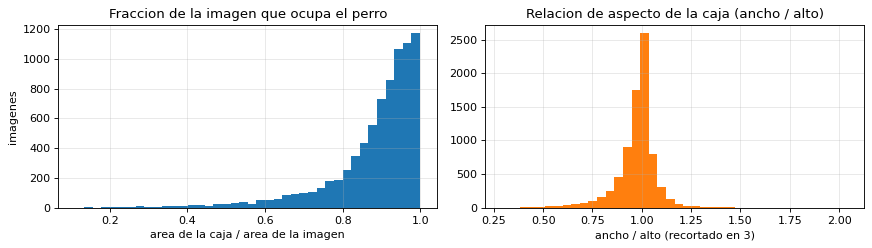

In [6]:
with_dog = yolo[yolo["n_dogs"] > 0]
print(f"Imagenes con al menos un perro detectado: {len(with_dog)} de {len(yolo)} ({len(with_dog) / len(yolo):.1%})")
display(with_dog[["dog_area_frac", "dog_box_aspect"]].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(3).T)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(with_dog["dog_area_frac"], bins=40, color="tab:blue")
axes[0].set(title="Fraccion de la imagen que ocupa el perro", xlabel="area de la caja / area de la imagen", ylabel="imagenes")
axes[1].hist(with_dog["dog_box_aspect"].clip(0, 3), bins=40, color="tab:orange")
axes[1].set(title="Relacion de aspecto de la caja (ancho / alto)", xlabel="ancho / alto (recortado en 3)")
fig.tight_layout()
plt.show()

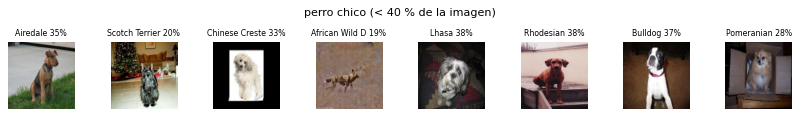

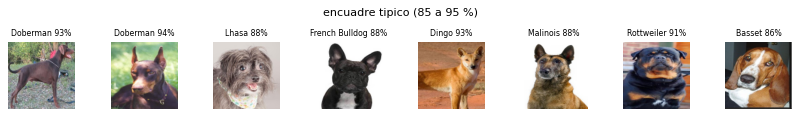

In [7]:
from lib.visualization.grid import show_grid

rng = np.random.default_rng(SEED)
groups = {
    "perro chico (< 40 % de la imagen)": with_dog[with_dog["dog_area_frac"] < 0.40],
    "encuadre tipico (85 a 95 %)": with_dog[with_dog["dog_area_frac"].between(0.85, 0.95)],
}
for label, frame in groups.items():
    sample = frame.sample(8, random_state=SEED)
    show_grid([DATASET / p for p in sample["path"]], [f"{b[:14]} {a:.0%}" for b, a in zip(sample["breed"], sample["dog_area_frac"])], cols=8, suptitle=label)
    plt.show()

**Lectura.** El dataset ya está muy "recortado": en la mitad de las imágenes el perro ocupa más del 90 % y
casi siempre hay un solo perro, centrado y en pose de foto. En ese sentido se parece a un recorte de YOLO,
pero hay diferencias que constituyen un **cambio de dominio** para la Etapa 3:

- **Resolución**: todas las imágenes son de 224 x 224. Un recorte de YOLO tiene la resolución del perro en la
  foto original: un perro chico o lejano da un recorte de pocos píxeles que hay que agrandar (pierde detalle),
  y uno grande da más detalle que el dataset.
- **Relación de aspecto**: en el dataset las cajas son casi cuadradas (mediana de ancho/alto 0,99) porque
  las imágenes son cuadradas y el perro las llena. En fotos reales la caja de YOLO toma la forma del perro
  (alargada si está de perfil o acostado). El preprocesamiento compartido conserva la proporción y rellena
  (padding) en lugar de estirar, para no deformar al perro.
- **Contenido del recorte**: la caja puede cortar patas o cabeza, o incluir parte de otro perro o de una
  persona; el dataset casi no tiene esos casos. La augmentation agrega recortes aleatorios desde los bordes
  para simularlo (sección 9).
- **Fotos no curadas**: el dataset tiene fotos elegidas a mano, en general de buena calidad. El conjunto
  independiente (sección 7) mide cuánto cae el rendimiento fuera de ese dominio.

### 4.3 Limitaciones del dataset

- **Razas muy parecidas** entre sí (Lhasa y Shih-Tzu, Boston Terrier y Bulldog, Cockapoo y Labradoodle,
  Border Collie y Collie, entre otras; se miden en la sección 5.3): son las que más va a confundir cualquier
  modelo.
- **Etiquetas inconsistentes y copias**: el control de calidad (sección 6) encontró la misma foto con dos
  razas distintas, cientos de duplicados dentro de `train` y, sobre todo, copias de imágenes de `train` en
  `valid` y `test` (fuga de datos). Sin limpiarlas, las métricas de `test` quedan infladas.
- **Sesgo de origen web**: son fotos de búsquedas de internet, muchas de perros de exposición, posados, con
  fondos limpios o blancos y buena iluminación. No representan fotos de celular de perros en la calle.
- **Taxonomía y mestizos**: no hay mestizos en general, pero sí dos cruzas "de diseño" (Cockapoo y
  Labradoodle), y hay categorías que no son razas independientes (Blenheim es una variedad de color del
  Cavalier King Charles). Un perro mestizo o de una raza fuera de las 70 va a recibir igual alguna de las 70:
  por eso la Etapa 1 tiene un umbral para responder "unknown".
- **Resolución baja (224 x 224)**: limita los detalles finos (textura del pelo, forma de las orejas) y obliga a
  agrandar las imágenes para el detector.
- **Tamaño**: unas 100 imágenes por raza en `train` y 10 en `valid` y `test`; las métricas por raza son
  ruidosas (sección 5.1).

## 5. Análisis exploratorio (EDA)

### 5.1 Distribución de clases

Imágenes por raza en cada split del dataset original (`splits_v0`).

,sum,mean,median,min,max,std,max_over_min
split,,,,,,,
train,7946.0,113.51,111.5,65.0,198.0,24.68,3.05
valid,700.0,10.00,10.0,10.0,10.0,0.00,1.00
test,700.0,10.00,10.0,10.0,10.0,0.00,1.00


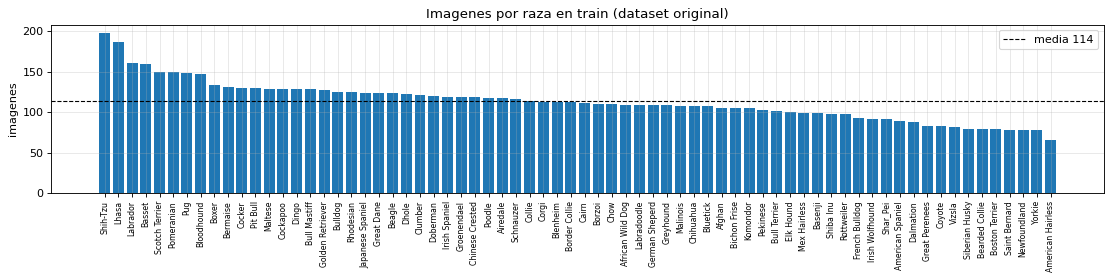

Razas con menos imagenes en train: {'Boston Terrier': 79, 'Saint Bernard': 78, 'Newfoundland': 78, 'Yorkie': 78, 'American Hairless': 65}
Razas con mas imagenes en train: {'Shih-Tzu': 198, 'Lhasa': 187, 'Labrador': 161, 'Basset': 159, 'Scotch Terrier': 150}
valid y test: exactamente [10] y [10] imagenes por raza


In [8]:
from lib.dataset.eda import class_counts, split_statistics, wilson_interval

counts = class_counts(v0)
display(split_statistics(counts))

order = counts["train"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(14, 3.6))
ax.bar(order.index, order.to_numpy(), color="tab:blue")
ax.axhline(order.mean(), color="black", linestyle="--", linewidth=1, label=f"media {order.mean():.0f}")
ax.set(title="Imagenes por raza en train (dataset original)", ylabel="imagenes")
ax.tick_params(axis="x", labelrotation=90, labelsize=7)
ax.legend()
fig.tight_layout()
plt.show()
print("Razas con menos imagenes en train:", order.tail(5).to_dict())
print("Razas con mas imagenes en train:", order.head(5).to_dict())
print("valid y test: exactamente", counts["valid"].unique(), "y", counts["test"].unique(), "imagenes por raza")

In [9]:
# Que precision tienen las metricas con 10 imagenes por raza y con 700 en total.
low, high = wilson_interval(8, 10)
print(f"Accuracy por raza 8/10 = 0,80 -> IC95 de Wilson [{low:.2f}, {high:.2f}] (ancho {high - low:.2f})")
p, n = 0.90, 700
se = (p * (1 - p) / n) ** 0.5
print(f"Accuracy global 0,90 con n = {n} -> error estandar {se:.3f}, IC95 aproximado +-{1.96 * se:.3f}")

Accuracy por raza 8/10 = 0,80 -> IC95 de Wilson [0.49, 0.94] (ancho 0.45)
Accuracy global 0,90 con n = 700 -> error estandar 0.011, IC95 aproximado +-0.022


**Desbalance.** `train` tiene entre 65 y 198 imágenes por raza (unas 3 veces de diferencia), mientras que
`valid` y `test` tienen exactamente 10 por raza. El desbalance de `train` puede sesgar al clasificador hacia las
razas con más imágenes; se evalúan pesos de clase al entrenar (Etapa 2). Como `valid` y `test` están
balanceados, la accuracy y las métricas macro casi coinciden.

**¿Alcanzan `valid` y `test`?** Para métricas **agregadas** sí: con 700 imágenes, una accuracy de 0,90 se
estima con un intervalo de unos +-2 puntos, suficiente para comparar modelos. Para métricas **por raza** no:
con 10 imágenes, un 8/10 tiene un intervalo de confianza que va de 0,49 a 0,94. Las métricas por raza se
reportan como descriptivas, no para sacar conclusiones raza por raza. Además, la limpieza (sección 6) obliga a
redefinir `valid` y `test` por la fuga de datos (sección 10).

### 5.2 Resoluciones, formato y archivos

Se leyó cada imagen con OpenCV y se verificó con PIL (detecta archivos truncados).

In [10]:
print("Extensiones:", v0["path"].str.rsplit(".", n=1).str[-1].str.lower().value_counts().to_dict())
print("Archivos ilegibles o corruptos:", int((~quality["readable"].astype(bool)).sum()))
res = quality.groupby(["height", "width", "channels"]).size().rename("imagenes").reset_index()
res["relacion_de_aspecto"] = res["width"] / res["height"]
display(res)

Extensiones: {'jpg': 9346}
Archivos ilegibles o corruptos: 0


,height,width,channels,imagenes,relacion_de_aspecto
0,224,224,3,9346,1.0


Todas las imágenes son JPG de 224 x 224 con 3 canales (RGB; ninguna en escala de grises) y ninguna está
corrupta: la distribución de ancho x alto y de relación de aspecto es un único punto (1:1), porque el autor
las redimensionó a ese tamaño. Ese redimensionado ya **estiró** las fotos originales no cuadradas: algunas
razas pueden verse levemente deformadas y no hay forma de recuperarlo.

### 5.3 Muestra visual y razas fáciles de confundir

Un ejemplo de cada raza (`train`):

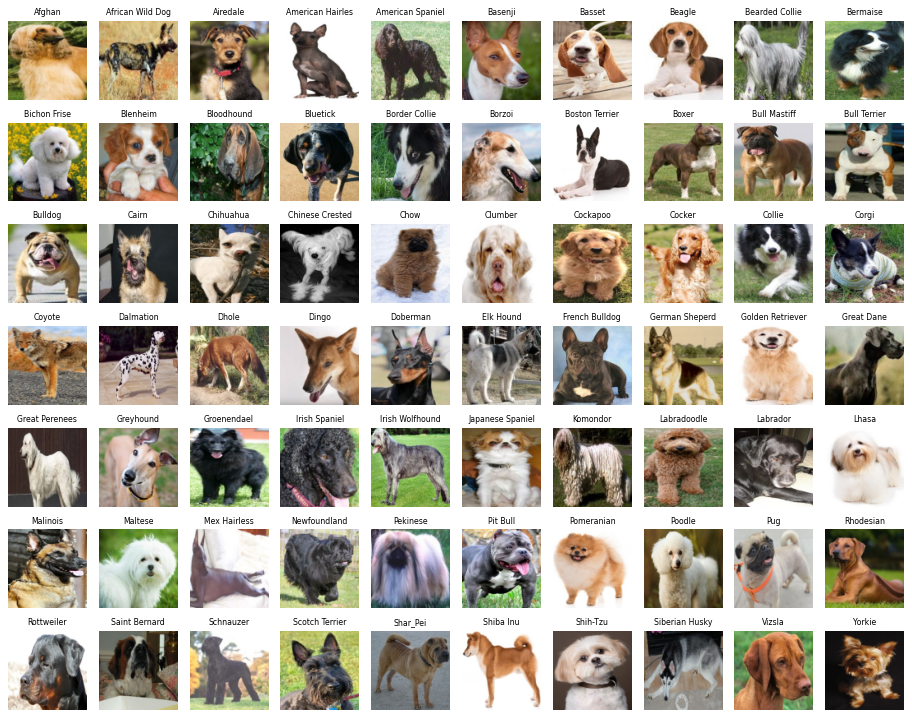

In [11]:
breeds = class_names(v0)
first = v0[v0["split"] == "train"].groupby("breed")["path"].first().reindex(breeds)
show_grid([DATASET / p for p in first], [b[:16] for b in breeds], cols=10, size=96, cell_inches=1.15, title_fontsize=7)
plt.show()

Para medir qué razas se confunden se usa el espacio de embeddings del baseline (ResNet50 de ImageNet, el
mismo de la Etapa 1): para cada imagen de `train` se busca su vecino más cercano (similitud coseno) y se cuenta
cuántas veces es de otra raza. Es exactamente el error que va a cometer la búsqueda por similitud. Se usa
`train` **ya limpio** (`splits_v1`, sección 10): con los duplicados, el vecino más cercano de una imagen sería
su propia copia y la medición quedaría distorsionada.

In [12]:
from lib.dataset.eda import nearest_neighbor_accuracy, nearest_neighbor_confusions

v1 = load_manifest(SPLITS_DIR / "splits_v1.csv")
row_of = pd.Series(np.arange(len(v0)), index=v0["path"])
train_v1 = v1[v1["split"] == "train"]
idx = row_of.loc[train_v1["path"]].to_numpy()
train_breeds = train_v1["breed"].to_numpy()

confusions = nearest_neighbor_confusions(embeddings[idx], train_breeds)
print(f"Imagenes de train (limpio) cuyo vecino mas cercano es de otra raza: {confusions['confused'].sum()} de {len(idx)}")
display(confusions.head(12)[["breed_a", "breed_b", "confused", "images_in_pair", "fraction"]].round(3))

acc = nearest_neighbor_accuracy(embeddings[idx], train_breeds)
print("Razas mas dificiles (fraccion de imagenes con vecino de la misma raza):", acc.head(6).round(2).to_dict())
print("Razas mas faciles:", acc.tail(6).round(2).to_dict())

Imagenes de train (limpio) cuyo vecino mas cercano es de otra raza: 660 de 7198


,breed_a,breed_b,confused,images_in_pair,fraction
0,Lhasa,Shih-Tzu,70,339,0.206
1,Boston Terrier,Bulldog,41,193,0.212
2,Cockapoo,Labradoodle,38,184,0.207
3,Border Collie,Collie,27,213,0.127
4,German Sheperd,Malinois,22,211,0.104
5,American Hairless,Mex Hairless,19,144,0.132
6,American Spaniel,Irish Spaniel,19,174,0.109
7,Groenendael,Malinois,12,211,0.057
8,Bichon Frise,Maltese,11,193,0.057
9,Labradoodle,Poodle,10,186,0.054


Razas mas dificiles (fraccion de imagenes con vecino de la misma raza): {'Lhasa': 0.65, 'Labradoodle': 0.67, 'Bulldog': 0.69, 'American Hairless': 0.73, 'Cockapoo': 0.73, 'American Spaniel': 0.74}
Razas mas faciles: {'Chow': 0.99, 'Bermaise': 1.0, 'Coyote': 1.0, 'Airedale': 1.0, 'Dalmation': 1.0, 'African Wild Dog': 1.0}


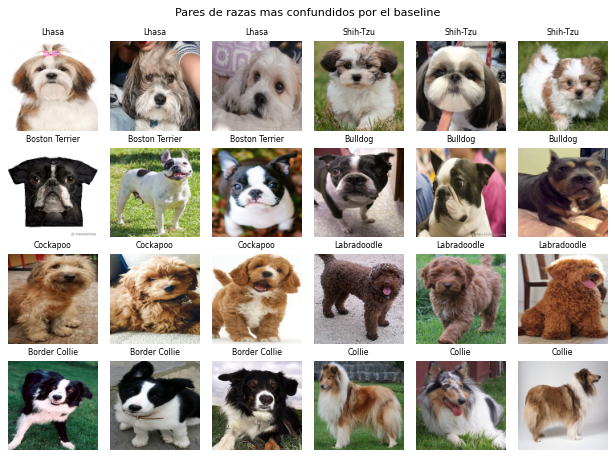

In [13]:
# Tres imagenes de cada raza de los cuatro pares mas confundidos.
paths, titles = [], []
for a, b in confusions.head(4)[["breed_a", "breed_b"]].itertuples(index=False):
    for breed in (a, b):
        pick = train_v1[train_v1["breed"] == breed].sample(3, random_state=SEED)
        paths += [DATASET / p for p in pick["path"]]
        titles += [breed[:16]] * 3
show_grid(paths, titles, cols=6, suptitle="Pares de razas mas confundidos por el baseline")
plt.show()

Los pares más confundidos son razas parecidas en tamaño, forma de la cabeza y pelaje, y varios son
variantes cercanas entre sí (las dos cruzas con caniche, Cockapoo y Labradoodle; los dos pastores belgas
y el alemán; las dos razas sin pelo). Son los pares que conviene incluir en el conjunto independiente
(sección 7) y mirar en el análisis de errores de la Etapa 2. En la prueba de la app de la Etapa 1, un Shiba
Inu de `test` se predijo como Dingo por el mismo motivo.

La grilla muestra además **ruido de etiqueta** que el filtrado automático no detecta: entre los Boston
Terrier hay una remera estampada (no es una foto de un perro) y algunos Bulldog se parecen más a un Boston
Terrier o a un Bulldog francés. Parte de la confusión medida entre esas razas viene de etiquetas dudosas,
no solo del parecido real.

### 5.4 Variaciones: iluminación, contenido de la escena, pose y fondo

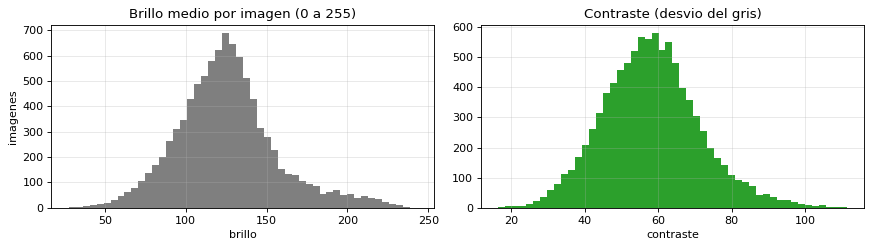

,count,mean,std,min,1%,50%,99%,max
brightness,9346.0,125.6,31.2,27.7,58.2,123.8,217.2,243.0
contrast,9346.0,58.2,13.3,16.5,29.8,57.8,94.3,111.3
blur_var,9346.0,1643.9,1891.9,24.7,91.1,1073.2,9236.2,36934.6


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(quality["brightness"], bins=50, color="tab:gray")
axes[0].set(title="Brillo medio por imagen (0 a 255)", xlabel="brillo", ylabel="imagenes")
axes[1].hist(quality["contrast"], bins=50, color="tab:green")
axes[1].set(title="Contraste (desvio del gris)", xlabel="contraste")
fig.tight_layout()
plt.show()
display(quality[["brightness", "contrast", "blur_var"]].describe(percentiles=[0.01, 0.5, 0.99]).round(1).T)

n_dogs,0,1,2,3 o mas
perros detectados,1510,7764,62,10


Imagenes con personas: 249 | con gatos y sin perro detectado: 220


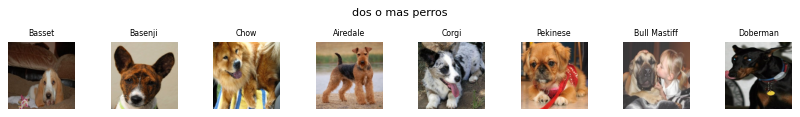

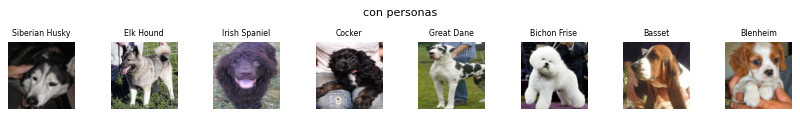

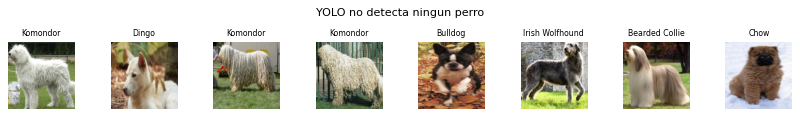

In [15]:
scene = pd.DataFrame(
    {
        "perros detectados": yolo["n_dogs"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3 o mas"}).value_counts().reindex(["0", "1", "2", "3 o mas"]),
    }
)
display(scene.T)
print("Imagenes con personas:", int((yolo["n_persons"] > 0).sum()), "| con gatos y sin perro detectado:", int(((yolo["n_cats"] > 0) & (yolo["n_dogs"] == 0)).sum()))

examples = {
    "dos o mas perros": yolo[yolo["n_dogs"] >= 2],
    "con personas": yolo[(yolo["n_persons"] > 0) & (yolo["n_dogs"] > 0)],
    "YOLO no detecta ningun perro": yolo[yolo["n_dogs"] == 0],
}
for label, frame in examples.items():
    sample = frame.sample(8, random_state=SEED)
    show_grid([DATASET / p for p in sample["path"]], [b[:16] for b in sample["breed"]], cols=8, suptitle=label)
    plt.show()

**Lectura.**

- **Iluminación**: el brillo medio va de imágenes muy oscuras a muy claras, pero los extremos son perros negros
  sobre fondo oscuro o blancos sobre fondo blanco, no fotos mal expuestas (se revisa en la sección 6). La
  augmentation agrega variaciones de brillo y contraste para cubrir fotos peor iluminadas que las del dataset.
- **Cantidad de perros**: casi todas las imágenes tienen un solo perro; las de dos o más son pocas (cachorros,
  parejas). En la Etapa 3 las escenas con varios perros van a ser frecuentes: el dataset no las representa.
- **Personas**: aparecen en una minoría de imágenes (dueños, exposiciones), en general parcialmente.
- **"Sin perro" según YOLO**: en las imágenes donde YOLO no detecta ningún perro sí hay un perro; son falsos
  negativos del detector (primeros planos, razas muy peludas como Komondor o Poodle, perros recortados). Por
  eso no se usa YOLO como regla automática de "sin perro visible" en el filtrado: descartaría imágenes buenas.
  También anticipa un límite de la Etapa 3: si YOLO no detecta al perro, el clasificador nunca lo ve.
- **Pose y fondo** (cualitativo, grillas de arriba): predominan poses de exposición (de perfil o de frente,
  parado o sentado), primeros planos de la cabeza y fondos de pasto, estudio o interiores; hay pocas
  oclusiones fuertes.

## 6. Control de calidad y filtrado

TO-DO: reglas explícitas y reproducibles (archivos corruptos, baja resolución, imágenes borrosas o
con exposición extrema, duplicados y casi-duplicados dentro y entre splits, imágenes mal etiquetadas).
Reportar cuántas imágenes descarta cada regla y mostrar ejemplos de descartes.

In [16]:
## TO-DO: reglas de filtrado, conteo de descartes por regla y ejemplos.

## 7. Conjunto independiente de evaluación

TO-DO: imágenes que no pertenezcan al dataset (internet o fotos propias), con las mismas razas que
las carpetas del dataset. Incluir imágenes con un perro (Etapas 1 y 2), escenas con varios perros u
otros objetos e imágenes sin perros (Etapa 3). Documentar fuente y licencia; no subirlas al repositorio.

In [17]:
## TO-DO: construcción y resumen del conjunto independiente (por ejemplo, en data/dataset/independent/<raza>/).

## 8. Preprocesamiento

TO-DO: definir y justificar el resize, la normalización y el orden de canales (la app entrega BGR).

⚠️ El mismo preprocesamiento debe usarse en las notebooks y en los servicios de la app:
encapsulalo en un módulo de `src/lib/` e importalo desde ambos lados.

In [18]:
## TO-DO: transformaciones de preprocesamiento (importadas desde el módulo compartido).

## 9. Data augmentation

TO-DO: horizontal flip, rotación, blur, variaciones de brillo y contraste y ruido, con sus rangos
justificados. Mostrar una grilla de ejemplos aumentados de una misma imagen. Solo sobre `train`.

In [19]:
## TO-DO: pipeline de data augmentation con ejemplos visuales.

## 10. Splits

TO-DO: definir train / validation / test (los del dataset o redefinidos, justificando), verificar
que no haya fuga de datos entre splits, fijar semillas y guardar los splits finales (CSV/JSON con
rutas y etiquetas) para `2-train.ipynb`.

In [20]:
## TO-DO: splits finales, verificación de fuga de datos y exportación.

## 11. Resumen final

TO-DO: tabla con la cantidad de razas e imágenes por split, incluido el conjunto independiente.

In [21]:
## TO-DO: tabla resumen.

## 12. Licencias y uso de imágenes

TO-DO: licencia del dataset, fuente y licencia de las imágenes del conjunto independiente y criterio
aplicado a imágenes con personas identificables.